# Sentiment analysis of product reviews

Is a product review positive or negative? This notebook compares five ways of representing review text, from a hand-built sentiment lexicon to a fine-tuned transformer, on the Multi-Domain Sentiment Dataset (Blitzer et al., 2007): Amazon reviews of books, DVDs, electronics and kitchen products. Each model is trained on one category and tested on all four, which also shows how well it carries over to a category it has not seen.

1. The data
2. Linguistic preprocessing with spaCy
3. What the text tells us
4. Text representations and models
5. Results within and across categories
6. Comparison with published results
7. Where the models go wrong

In [1]:
import json
import sys
sys.path.insert(0, "..")

import pandas as pd

from review_sentiment import analysis, plots, published
from review_sentiment.data import DOMAINS, LABELS, RESULTS_DIR, add_split, load_reviews, parse, raw_path
from review_sentiment.evaluate import (FINE_TUNED, TFIDF, accuracy_matrix, bootstrap_ci, load_transformer_predictions,
                                       run_classic_models, summary)
from review_sentiment.experiments import best_variant, preprocessing_experiments
from review_sentiment.features import load_glove
from review_sentiment.preprocess import analyse, load_nlp, process

pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 140)
reviews = add_split(load_reviews())  # downloads the data the first time
reviews.head()

,domain,label,title,text,split
0,books,0,"Horrible book, horrible.",THis book was horrible. If it was possible to rate it lower than one star i would have. I am an avid reader and picked this book up af...,train
1,books,0,shallow self-indulgence,"I like to use the Amazon reviews when purchasing books, especially alert for dissenting perceptions about higly rated items, which usual...",train
2,books,0,Disappointment,"I'm not sure who's writing these reviews, but I read repitition after repitition after repitition, with a lot of confusing fluff. Asking...",train
3,books,0,A Disappointing Mess,"I picked up the first book in this series (The Eyre Affair) based purely on its premise and was left somewhat underwhelmed. Still, the p...",train
4,books,0,"Save your money, there are better books out there","Not only do I disagree with his opinions, but some of his facts are blatently false. On page 106 he refers to violence agains Native Am...",train


## 1. The data

In [2]:
in_files = sum(len(parse(raw_path(d, l).read_text(encoding="utf-8"))) for d in DOMAINS for l in LABELS)
print(f"{in_files} reviews in the files, {len(reviews)} after removing {in_files - len(reviews)} duplicates")
reviews.groupby(["domain", "label"]).size().unstack().rename(columns=dict(enumerate(LABELS)))

8000 reviews in the files, 7853 after removing 147 duplicates


label,negative,positive
domain,,
books,963,993
dvd,959,995
electronics,979,987
kitchen,981,996


Each category has 1,000 positive reviews (4 or 5 stars) and 1,000 negative ones (1 or 2 stars). Some reviews appear twice in the same category with exactly the same text; the copies are removed before splitting, otherwise a review could end up in both the training and the test data. Each category is then split 80/20, keeping the share of positive reviews:

In [3]:
pd.crosstab(reviews["domain"], reviews["split"])

split,test,train
domain,,
books,392,1564
dvd,391,1563
electronics,394,1572
kitchen,396,1581


## 2. Linguistic preprocessing with spaCy

spaCy's small English pipeline tokenizes each review, tags parts of speech, parses it and lemmatizes it. Negation needs special care: a bag of words sees "good" in "not good". Following Das and Chen (2001) and Pang et al. (2002), every word between a negation and the next punctuation mark gets a `NOT_` prefix. Negations are found by the parser (the `neg` dependency, as in "n't") and a short word list.

In [4]:
nlp = load_nlp()
example = nlp("I wouldn't buy this blender again: not sturdy at all, but the price was great!")
pd.DataFrame([(t.text, t.lemma_, t.pos_, t.dep_) for t in example],
             columns=["token", "lemma", "part of speech", "dependency"]).T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
token,I,would,n't,buy,this,blender,again,:,not,sturdy,at,all,",",but,the,price,was,great,!
lemma,I,would,not,buy,this,blender,again,:,not,sturdy,at,all,",",but,the,price,be,great,!
part of speech,PRON,AUX,PART,VERB,DET,NOUN,ADV,PUNCT,PART,ADJ,ADV,ADV,PUNCT,CCONJ,DET,NOUN,AUX,ADJ,PUNCT
dependency,nsubj,aux,neg,ROOT,det,dobj,advmod,punct,neg,dep,advmod,advmod,punct,cc,det,nsubj,conj,acomp,punct


In [5]:
analyse(example)

{'tokens': "i would n't buy this blender again not sturdy at all but the price was great",
 'lemmas': 'i would not buy this blender again not sturdy at all but the price be great',
 'tokens_negation': "i would n't NOT_buy NOT_this NOT_blender NOT_again not NOT_sturdy NOT_at NOT_all but the price was great",
 'lemmas_negation': 'i would not NOT_buy NOT_this NOT_blender NOT_again not NOT_sturdy NOT_at NOT_all but the price be great',
 'n_words': 16,
 'n_sentences': 1,
 'n_negations': 2,
 'n_exclamations': 1,
 'n_adj': 2,
 'n_adv': 3,
 'n_verb': 1,
 'n_noun': 2}

In [6]:
processed = process(reviews)  # about a minute the first time, then read from the cache
processed[["lemmas_negation", "n_words", "n_sentences", "n_negations", "n_adj"]].head()

,lemmas_negation,n_words,n_sentences,n_negations,n_adj
0,horrible book horrible this book be horrible if it be possible to rate it low than one star i would have i be an avid reader and pick th...,114,9,0,11
1,shallow self indulgence i like to use the amazon review when purchase book especially alert for dissent perception about higly rat item ...,102,5,1,7
2,disappointment i be not NOT_sure NOT_who NOT_be NOT_write NOT_these NOT_review but i read repitition after repitition after repitition w...,85,9,4,10
3,a disappointing mess i pick up the first book in this series the eyre affair base purely on its premise and be leave somewhat underwhelm...,604,23,6,59
4,save your money there be well book out there not NOT_only NOT_do NOT_i NOT_disagree NOT_with NOT_his NOT_opinion but some of his fact be...,59,4,3,5


## 3. What the text tells us

In [7]:
stats = analysis.text_statistics(reviews, processed)
stats

reviews    words  sentences  negations per 100 words  \
domain      sentiment                                                         
books       negative       963  186.553     10.739                    1.875   
            positive       993  176.800     10.033                    1.164   
dvd         negative       959  167.618     10.433                    1.996   
            positive       995  184.993     10.896                    1.297   
electronics negative       979  117.902      8.483                    2.465   
            positive       987  116.573      8.050                    1.733   
kitchen     negative       981   99.403      7.409                    2.311   
            positive       996   98.563      7.237                    1.713   

                       adjectives per 100 words  \
domain      sentiment                             
books       negative                      8.405   
            positive                      8.807   
dvd         negative                      8.449   
            positive                      8.390   
electronics negative                      7.170   
            positive                      8.585   
kitchen     negative                      7.587   
            positive                      9.361   

                       exclamation marks per 100 words  
domain      sentiment                                   
books       negative                             0.317  
            positive                             0.349  
dvd         negative                             0.532  
            positive                             0.603  
electronics negative                             0.581  
            positive                             0.536  
kitchen     negative                             0.740  
            positive                             1.011

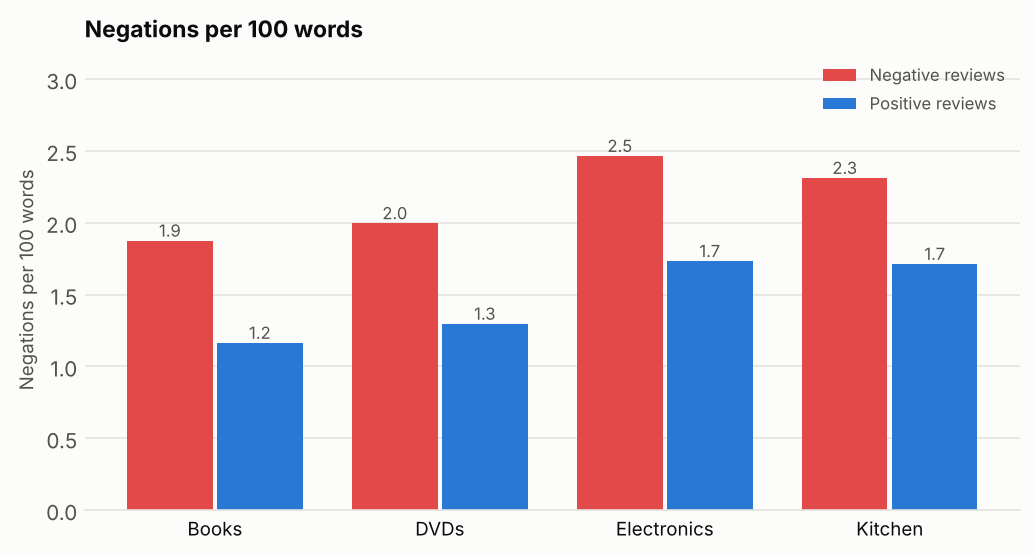

In [8]:
fig = plots.plot_text_statistics(stats, "negations per 100 words")

In every category negative reviews use 1.35 to 1.6 times as many negations as positive ones. Electronics and kitchen reviews are much shorter than book and DVD reviews, and positive kitchen reviews use the most adjectives and exclamation marks.

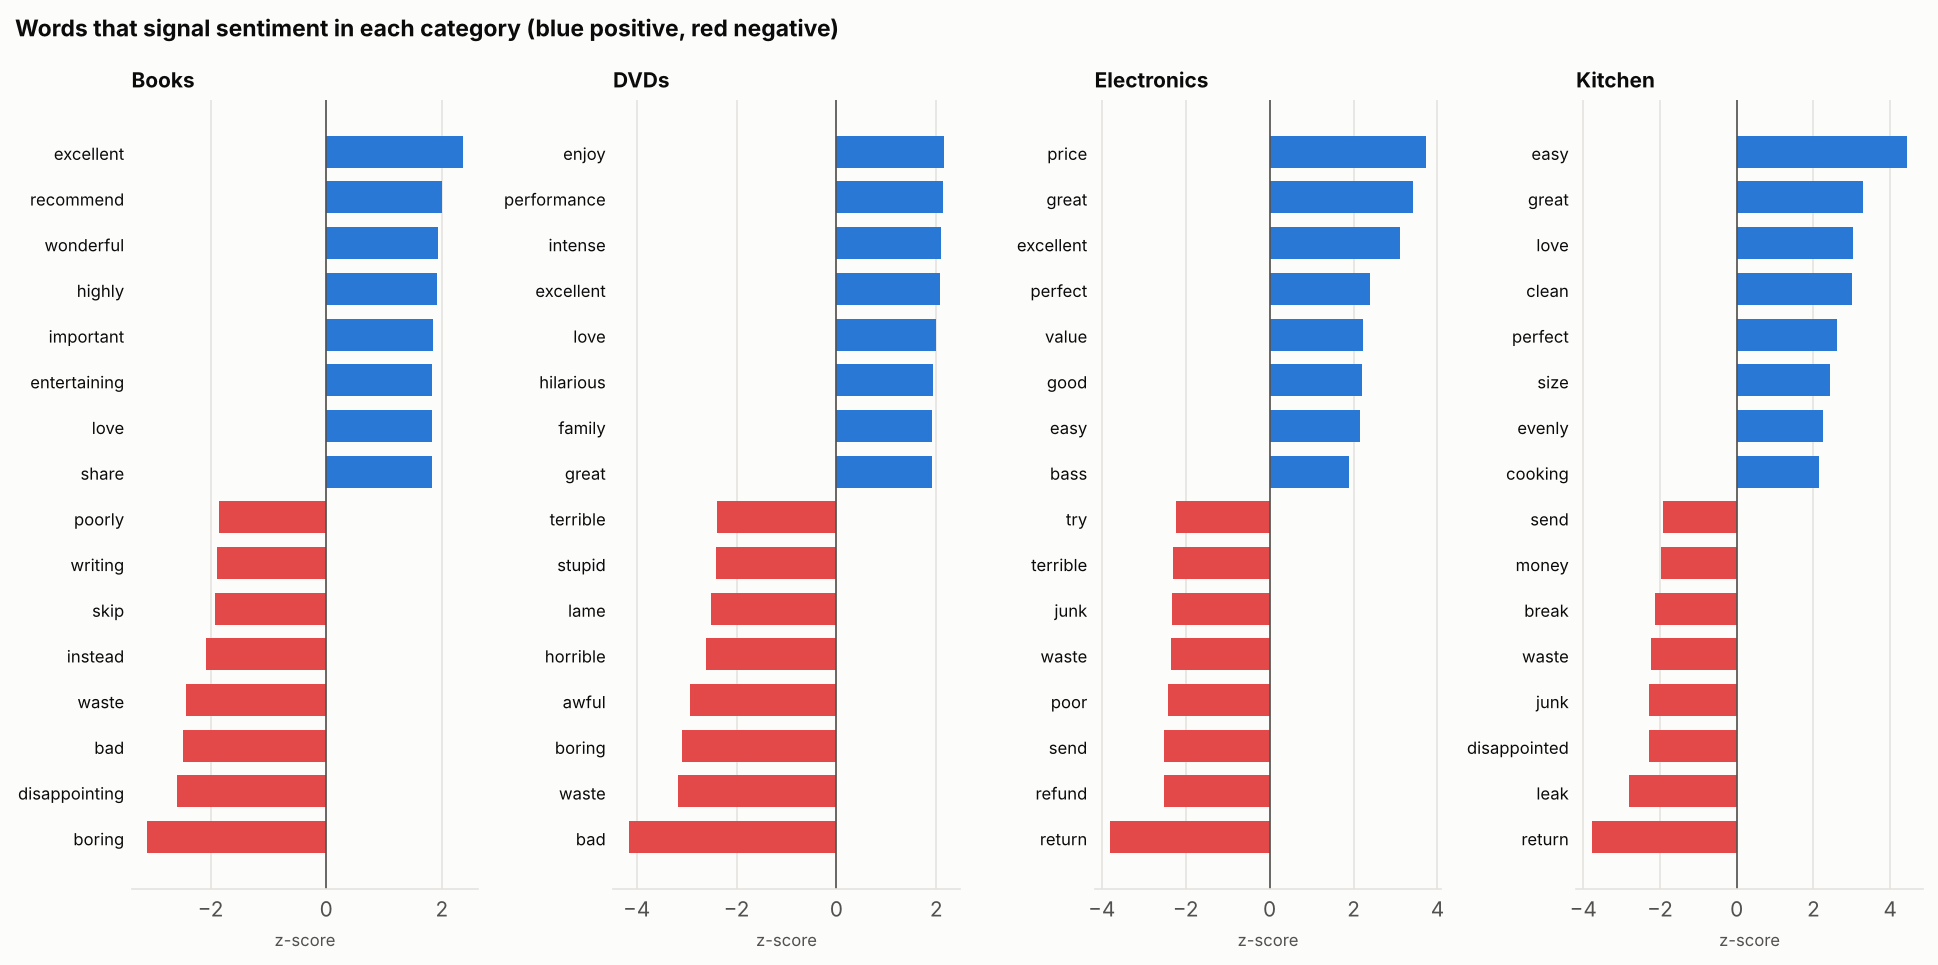

In [9]:
z_scores = analysis.sentiment_z_scores(reviews, processed)
fig = plots.plot_sentiment_words(z_scores)

Words are ranked by how strongly they separate positive from negative reviews, with the log-odds ratio and an informative Dirichlet prior (Monroe, Colaresi and Quinn, 2008), computed on training reviews only and counting each word once per review. Book and DVD reviewers judge the content ("boring", "writing", "performance", "hilarious"); electronics and kitchen reviewers judge the product and the purchase ("return", "refund", "leak", "sturdy", "easy").

In [10]:
overlap = analysis.vocabulary_overlap(z_scores)
overlap

,books,dvd,electronics,kitchen
books,1.00,0.22,0.10,0.14
dvd,0.22,1.00,0.11,0.18
electronics,0.10,0.11,1.00,0.25
kitchen,0.14,0.18,0.25,1.00


Share of each category's 100 strongest sentiment words that are also among the 100 strongest of another category. Books and DVDs share 22.0%, electronics and kitchen 25.0%, but books and electronics only 10.0%. Section 5 shows that this overlap predicts how well a model transfers from one category to another.

## 4. Text representations and models

Five representations, all trained separately on each category:

- **VADER lexicon** (Hutto and Gilbert, 2014): hand-built sentiment rules, with negation, intensifiers and punctuation. Nothing is learned except the cut-off between positive and negative, chosen on the training reviews.
- **TF-IDF**: sparse vectors of lemma unigrams and bigrams with negation marking, and a logistic regression.
- **GloVe**: the average of 300-dimensional pretrained word vectors (Pennington et al., 2014), and a logistic regression.
- **RoBERTa embeddings**: the average of the contextual token vectors of a frozen RoBERTa-base encoder, and a logistic regression.
- **Fine-tuned RoBERTa**: the same encoder with a new output layer, trained on the reviews.

Every logistic regression has its regularisation chosen by 5-fold cross-validation on the training reviews. First, which preprocessing steps help the TF-IDF model, scored by cross-validation on the training reviews only:

In [11]:
experiments = preprocessing_experiments(reviews, processed)
experiments

,books,dvd,electronics,kitchen,average
Words,0.831,0.832,0.854,0.870,0.847
Lemmas,0.838,0.834,0.840,0.858,0.843
Words and bigrams,0.838,0.843,0.867,0.889,0.859
Lemmas and bigrams,0.842,0.843,0.870,0.877,0.858
"Words and bigrams, negation marked",0.838,0.844,0.882,0.893,0.864
"Lemmas and bigrams, negation marked",0.841,0.852,0.880,0.886,0.865


Lemmatization alone does not help (84.7% with words, 84.3% with lemmas). Tense carries sentiment in product reviews: in electronics and kitchen reviews "works" leans positive and "worked" negative ("it worked for two weeks"), and lemmatization merges both into "work". Bigrams help most (85.9% with words, 85.8% with lemmas) and negation marking adds a little more (86.4% and 86.5%). With both, words and lemmas are tied; the TF-IDF model uses the best variant, lemmas and bigrams, negation marked.

The two RoBERTa models are slow on a CPU, so they are run once with `python -m review_sentiment.transformer` and their predictions saved in `results/`. RoBERTa-base comes from spaCy's `en_core_web_trf` pipeline. Fine-tuning trains the top 6 of its 12 layers and the new output layer for 3 epochs and keeps the first epoch with the best accuracy on 10% of the training reviews:

In [12]:
variant, column, ngram_range = best_variant(experiments)
print("TF-IDF uses:", variant)
preds = pd.concat([run_classic_models(reviews, processed, load_glove(), column, ngram_range),
                   load_transformer_predictions(RESULTS_DIR)], ignore_index=True)
histories = {d: json.loads((RESULTS_DIR / f"finetuned_{d}_history.json").read_text()) for d in DOMAINS}
pd.DataFrame({d: [epoch["val_accuracy"] for epoch in h] for d, h in histories.items()},
             index=pd.Index([1, 2, 3], name="epoch"))  # fine-tuning: validation accuracy per epoch

TF-IDF uses: Lemmas and bigrams, negation marked


,books,dvd,electronics,kitchen
epoch,,,,
1,0.866,0.847,0.911,0.881
2,0.924,0.911,0.899,0.899
3,0.911,0.898,0.911,0.906


The best epoch is the second for books and DVDs and the third for kitchen. For electronics the first and the third tie, and the rule keeps the first. The validation sets are small (about 160 reviews), so the choice of epoch is noisy.

## 5. Results within and across categories

In [13]:
table = summary(preds)
table["95% CI"] = [" to ".join(f"{v:.1%}" for v in bootstrap_ci(preds, model)) for model in table.index]
table

,books,dvd,electronics,kitchen,in-category,cross-category,drop,95% CI
VADER lexicon,0.686,0.721,0.782,0.826,0.754,0.753,0.001,73.2% to 77.5%
TF-IDF,0.837,0.839,0.916,0.896,0.872,0.789,0.083,85.7% to 88.8%
GloVe,0.791,0.780,0.817,0.836,0.806,0.721,0.085,78.8% to 82.5%
RoBERTa embeddings,0.770,0.747,0.822,0.851,0.798,0.743,0.054,77.8% to 81.8%
Fine-tuned RoBERTa,0.885,0.870,0.898,0.937,0.898,0.883,0.014,88.2% to 91.2%


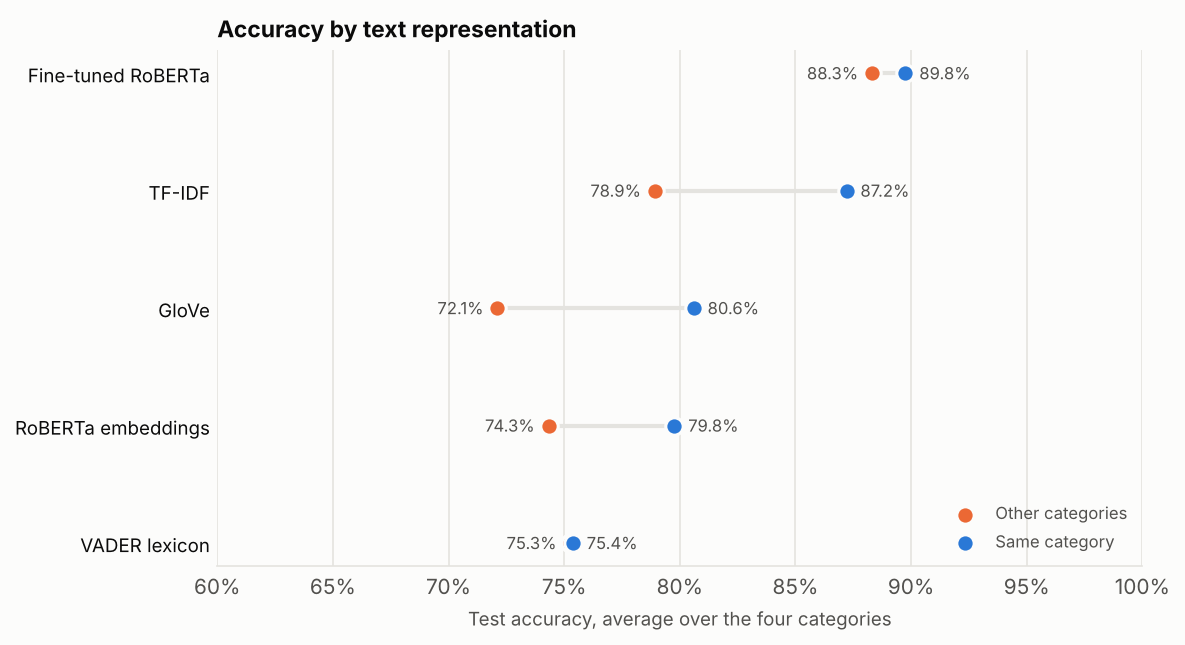

In [14]:
fig = plots.plot_accuracy(table)

Fine-tuned RoBERTa is the most accurate model: 89.8% on the category it was trained on, 2.6 points above TF-IDF (87.2%). Frozen, the same encoder is no better than averaged GloVe vectors (79.8% against 80.6%): its token vectors were not trained for sentiment, and averaging them over a whole review blurs them further. VADER needs no training data but stays at 75.4%.

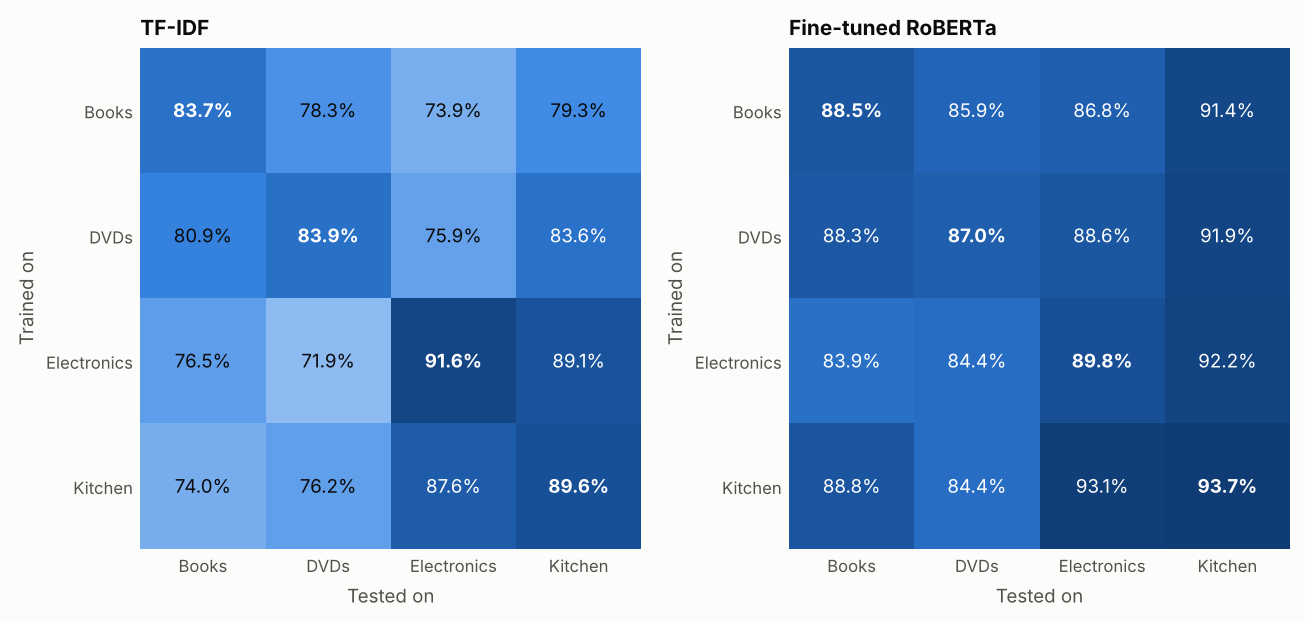

In [15]:
matrices = {model: accuracy_matrix(preds, model) for model in (TFIDF, FINE_TUNED)}
fig = plots.plot_accuracy_matrices(matrices)

Rows are the training category and columns the test category, so the diagonal is in-category accuracy. TF-IDF loses 8.3 points on average when the category changes; fine-tuned RoBERTa only 1.5, because what it learned in pretraining about language carries over, while TF-IDF only knows the words of its training category.

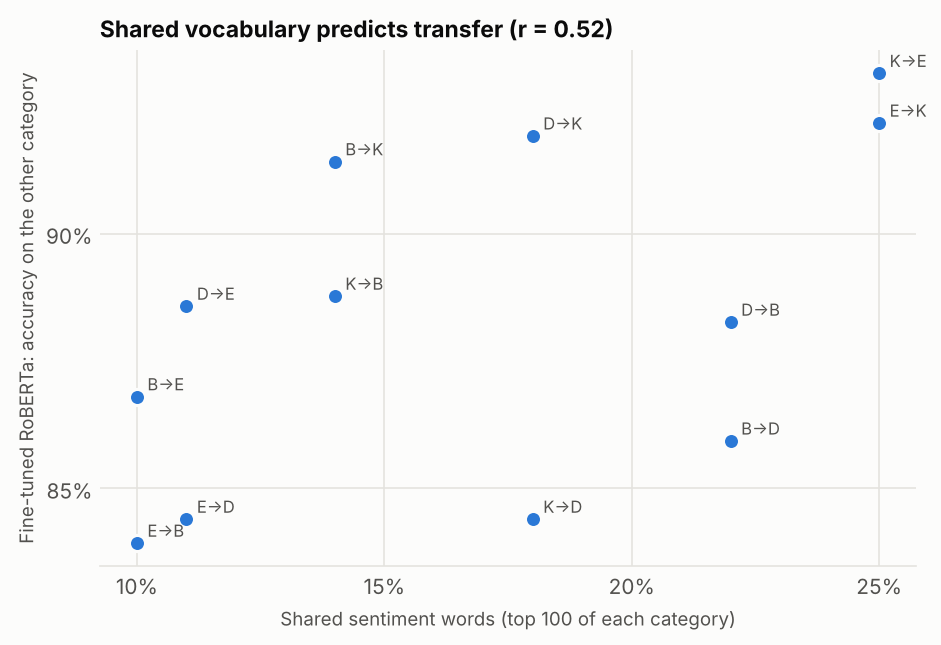

In [16]:
fig = plots.plot_overlap_vs_transfer(overlap, matrices[FINE_TUNED], FINE_TUNED)

Each point is a pair of training and test categories. The more sentiment words two categories share, the better TF-IDF trained on one works on the other (r = 0.82). For fine-tuned RoBERTa the link is weaker (r = 0.52): what it learned in pretraining does not depend on the words of one category.

## 6. Comparison with published results

In [17]:
published.in_category_table(table, [TFIDF, FINE_TUNED])

,books,dvd,electronics,kitchen,Average
"Blitzer et al. (2007), linear model on unigrams and bigrams",0.804,0.824,0.844,0.877,0.837
This project: TF-IDF,0.837,0.839,0.916,0.896,0.872
This project: Fine-tuned RoBERTa,0.885,0.870,0.898,0.937,0.898


In [18]:
published.cross_category_table(table, [TFIDF, FINE_TUNED]).to_frame()

,"Average accuracy, 12 category pairs"
"Blitzer et al. (2007), linear model, no adaptation",0.745
"Blitzer et al. (2007), SCL-MI, adapted with unlabelled target reviews",0.780
"Karouzos et al. (2021), BERT-base fine-tuned on the source category",0.899
"Karouzos et al. (2021), UDALM, adapted with unlabelled target reviews",0.917
"This project: TF-IDF, no adaptation",0.789
"This project: Fine-tuned RoBERTa, no adaptation",0.883


Blitzer et al. (2007) trained a linear model on unigrams and bigrams with 1,600 reviews per category and tested on 400; Karouzos et al. (2021) fine-tuned BERT-base on 1,600 reviews and tested on all 2,000 of the other category. This project removes duplicates, tests on about 390 reviews per category and, to fit a CPU, trains RoBERTa on about 1,400 reviews with half of its layers frozen, so the comparison is indicative. TF-IDF with negation marking beats the original linear model in every category, and fine-tuned RoBERTa comes within 1.6 points of the published BERT result across categories.

## 7. Where the models go wrong

In [19]:
errors = analysis.confident_errors(preds, reviews, FINE_TUNED, n=8)
errors.assign(text=errors["text"].str.slice(0, 300))

,domain,title,text,sentiment,score
review,,,,,
7272,kitchen,It Really Does Fit,"I was a little dubious about this item. Some of the reviews indicated that it did not really have deep pockets. Well, I can tell you t...",positive,0.002
5586,electronics,Unbreakable,I bought a 32 inch 5 years ago. in 2003 when movie I was trying to move it across the room and it flipped face first in the floor. Min...,positive,0.003
151,books,This is a great book...,This is a great book if you have the right teacher. The book is very informative yet if you have no back ground in abnormal psych you mi...,negative,0.996
6667,kitchen,So So,"My kitchen is entirely Kitchenaid, so I was very excited when Kitchenaid released their silicone bakeware line. I love the color and the...",negative,0.996
7582,kitchen,completly satisfied,I couldn't be more satisfied if my stock pot had cost 10 times as much,positive,0.004
7761,kitchen,NEVER put a carbon steel knife into the dishwasher!,Lisa S from Ohio complains that the knives rust very easily and that this is a buyer-beware item. This is not a buyer beware item. This...,positive,0.004
6793,kitchen,Nowhere near as good as genuine Wusthof or Henckels...,"I recently got this set and the 2 piece carving set of the same series. I know I should not have expected much for this great price, but...",negative,0.995
7234,kitchen,Different pattern compared to usual correlle stuff,Got damaged in shipping ...but amazon happily replaced with a new one..Great CS amazon.Thanks\n\nHad to send back the broken one back to...,positive,0.005


The most confident mistakes have recognisable causes:

- **Rebuttals of other reviews**, which repeat the complaints they answer: "do not believe the nay-sayers", or a positive review titled "NEVER put a carbon steel knife into the dishwasher!"
- **Stories of a mishap with a happy ending**: a TV that survived a fall, a dish broken in shipping and replaced.
- **A negated comparison**: "I couldn't be more satisfied if my stock pot had cost 10 times as much."
- **Praise before the complaint**: a review that loves the colour and the easy cleaning, then turns with "However, I have noticed...".
- **Comparisons with other brands**: "Nowhere near as good as genuine Wusthof or Henckels".

A few low ratings read as mild ("a great book if you have the right teacher"): star ratings are a noisy label.

In [20]:
fixed = analysis.disagreements(preds, reviews, FINE_TUNED, TFIDF)
broken = analysis.disagreements(preds, reviews, TFIDF, FINE_TUNED)
print(f"{len(fixed)} test reviews right only with {FINE_TUNED}, {len(broken)} right only with {TFIDF}")
products = fixed[fixed["domain"].isin(["electronics", "kitchen"])]  # examples from the product categories
products.assign(text=products["text"].str.slice(0, 250)).head(6)

122 test reviews right only with Fine-tuned RoBERTa, 82 right only with TF-IDF


,domain,title,text,sentiment,Fine-tuned RoBERTa,TF-IDF
review,,,,,,
3963,electronics,"Great Features, Unreliable Connections","I like the features. I'm satisfied with the sound. The user interface could be more intuitive.\n\nHOWEVER, my overriding complaint is ...",negative,0.009,0.563
4009,electronics,Install CD has viruses,I just recently bought this and when I installed it Norton caught 2 viruses on the install CD.,negative,0.007,0.536
4283,electronics,Could be better,"The sound is really great, but there is one problem with this headphones they keep falling from my ears no matter what rubber caps (they...",negative,0.013,0.568
4293,electronics,Thrown Together Phone,"It looked flashy and well-conceived on the web shopping sites that featured it; however, after setting up Panasonic's KX-TG5576M, I'm un...",negative,0.045,0.543
4306,electronics,"Powerline ethernet works great, wireless no so","I bought this to run ethernet into my daughter's room. The powerline etherernet works flawlessly, I've had it up and running for six mo...",negative,0.133,0.656
4340,electronics,The clip is better,"I bought the armband when I got my mini ipod. However, the belt clip that comes with the iPod is perfect to clip to my shorts while jogg...",negative,0.426,0.622


Many reviews that only fine-tuned RoBERTa gets right are mixed: praise first, then the complaint that decides the rating ("The sound is really great, but ... The design flaw makes them unusable for me"; "HOWEVER, my overriding complaint is..."). TF-IDF adds up the positive words, while RoBERTa reads the turn. Others need knowledge rather than sentiment words, such as "Install CD has viruses".

## Conclusions

- Fine-tuned RoBERTa is the best model: 89.8% on the category it was trained on and 88.3% on the others.
- A well preprocessed TF-IDF model is a strong baseline (87.2%), above the original linear model of Blitzer et al. (2007), at a tiny fraction of the cost.
- Contextual embeddings need fine-tuning: frozen and averaged, RoBERTa is no better than GloVe.
- Changing category costs TF-IDF 8.3 points and fine-tuned RoBERTa only 1.5. How much two categories share their sentiment vocabulary predicts how well a model transfers between them.
- Negation is a strong cue; marking its scope is the most useful preprocessing step for TF-IDF.